# Messi Club Career Goals: Linking Data Space and Projection Space with PCA and UMAP

**Course:** Data Visualization, UNC Charlotte  |  **Team:** Essey Beraki, Sam Banstola, Luis Chavez
**Data:** `data.csv` from the team repo (704 club goals, 13 raw columns)

This notebook extends our earlier Messi project. It does three things:

1. Applies **one linear** (PCA) and **one non-linear** (UMAP) dimension reduction (DR) method to a multi-dimensional description of each goal.
2. **Compares data space and projection space** with side-by-side figures and quantitative checks.
3. Provides an **interactive dashboard** where brushing in either projection, the parallel-coordinates view, the season timeline, or the bar charts highlights the same goals everywhere.

| Rubric item | Where |
|---|---|
| 1. Two DR methods (2 pts) | Section 3 |
| 2. Data space vs. projection space (2 pts) | Sections 4 to 5 |
| 3. Interactive joint exploration (4 pts) | Sections 6 to 7 |
| 4. Peer evaluation | Section 10 |
| 5. Documentation and reporting (2 pts) | Whole notebook, plus Sections 8 to 9 |

> **Note on the data.** `data.csv` contains no shot x/y coordinates (those are in the separate Hudl open data, which is not joined here), so a pitch map is not part of this notebook. Every goal is described by match context, shot type, opponent, and score situation instead.

## 1. Setup

In [1]:
import json, re, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import altair as alt
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness
from sklearn.neighbors import NearestNeighbors
from sklearn.datasets import make_swiss_roll
import umap

warnings.filterwarnings("ignore")
alt.data_transformers.disable_max_rows()
SEED = 42
np.random.seed(SEED)

# Color-blind-validated categorical slots (blue, orange, aqua) plus a neutral gray for "Other"
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#b9b8b2"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 9, "font.size": 9})

DATA_PATH = "data.csv" if os.path.exists("data.csv") else \
    "https://raw.githubusercontent.com/ashgithub0208/Lionel_Messi_Club_Career_Analysis/main/data.csv"
raw = pd.read_csv(DATA_PATH)
print(raw.shape)
raw.head(3)

(704, 13)


,Season,Competition,Matchday,Date,Venue,Club,Opponent,Result,Playing_Position,Minute,At_score,Type,Goal_assist
0,04/05,LaLiga,34,05-01/05,H,FC Barcelona,Albacete Balompie,2:00,CF,90+1,2:00,Left-footed shot,Ronaldinho Gaacho
1,05/06,UEFA Champions League,Group Stage,11-02/05,H,FC Barcelona,Panathinaikos Athens,5:00,RW,34,3:00,Left-footed shot,NaN
2,05/06,LaLiga,13,11/27/05,H,FC Barcelona,Racing Santander,4:01,RW,51,2:00,Left-footed shot,Samuel Etoo


## 2. Data preparation

The raw file has several quirks (Excel type-guessing damaged some columns), so we clean before building features:

- `Result` and `At_score` look like times (`2:00`) but are scores written `home:away` (`2:00` is 2-0). We confirm this below and convert them to **Messi's team first**.
- `Season` has two values mangled into dates (`11-Dec` is 2011/12 and `Dec-13` is 2012/13).
- `Playing_Position` has trailing spaces, `Competition` has duplicate spellings, and `Minute` includes stoppage time (`90+1`).
- `Matchday` mixes league round numbers with cup stages, which we group into a `Stage` column (same idea as the README).

In [2]:
df = raw.copy()

# --- text fixes -------------------------------------------------------------
df["Playing_Position"] = df["Playing_Position"].str.strip()
df["Competition"] = (df["Competition"].str.replace("\ufffd", "\u00e9", regex=False)
                     .replace({"Champions League": "UEFA Champions League"}))
df["Season"] = df["Season"].replace({"11-Dec": "11/12", "Dec-13": "12/13"})
season_order = sorted(df["Season"].unique())
df["season_idx"] = df["Season"].map({s: i for i, s in enumerate(season_order)})

# --- stage ------------------------------------------------------------------
def stage(m):
    m = str(m).strip().lower()
    if m.isdigit(): return "League matchday"
    if m == "group stage": return "Group stage"
    if m in ("last 16", "round of 16"): return "Round of 16"
    if "round" in m: return "Early cup round"
    if m.startswith("quarter"): return "Quarter-finals"
    if m.startswith("semi"): return "Semi-finals"
    if m == "final": return "Final"
    return "Other"
df["Stage"] = df["Matchday"].map(stage)

# --- minute (90+1 -> 91) ----------------------------------------------------
def minute(s):
    a, _, b = str(s).partition("+")
    return int(a) + (int(b) if b else 0)
df["minute"] = df["Minute"].map(minute)

# --- scores: home:away -> Messi's team first -------------------------------
def parse_score(s):
    m = re.match(r"(\d+):(\d+)", str(s))
    return int(m.group(1)), int(m.group(2))
res = df["Result"].map(parse_score); at = df["At_score"].map(parse_score)
home = df["Venue"].eq("H")
df["team_final"] = np.where(home, [r[0] for r in res], [r[1] for r in res])
df["opp_final"]  = np.where(home, [r[1] for r in res], [r[0] for r in res])
df["team_at"]    = np.where(home, [a[0] for a in at],  [a[1] for a in at])
df["opp_at"]     = np.where(home, [a[1] for a in at],  [a[0] for a in at])

# sanity checks that the home:away interpretation is right
assert (df["team_at"] >= 1).all(), "At_score should be the score right after Messi's goal"
assert (df["team_final"] >= df["team_at"]).all() and (df["opp_final"] >= df["opp_at"]).all()
print("Messi's team won/drew/lost (share of goals scored in...):",
      {"win": round((df.team_final > df.opp_final).mean(), 2),
       "draw": round((df.team_final == df.opp_final).mean(), 2),
       "loss": round((df.team_final < df.opp_final).mean(), 2)})

# --- grouped categoricals (keep the feature space compact) -----------------
df["has_assist"] = df["Goal_assist"].notna().astype(int)
df["Type_Clean"] = df["Type"].where(df["Type"].isin(
    ["Left-footed shot", "Right-footed shot", "Penalty", "Direct free kick", "Header"]), "Other")
df["Competition_Group"] = df["Competition"].where(df["Competition"].isin(
    ["LaLiga", "UEFA Champions League", "Copa del Rey", "Ligue 1"]), "Other cups")
df["Position"] = df["Playing_Position"].where(df["Playing_Position"].isin(["CF", "RW", "SS"]), "AM/LW")
top_opp = df["Opponent"].value_counts().head(8).index
df["Opponent_Group"] = df["Opponent"].where(df["Opponent"].isin(top_opp), "Other opponent")
df["Venue_Label"] = np.where(home, "Home", "Away")

df[["Season", "Competition_Group", "Stage", "minute", "team_at", "opp_at", "team_final", "opp_final",
    "Type_Clean", "Opponent_Group"]].head()

Messi's team won/drew/lost (share of goals scored in...): {'win': np.float64(0.89), 'draw': np.float64(0.08), 'loss': np.float64(0.03)}


,Season,Competition_Group,Stage,minute,team_at,opp_at,team_final,opp_final,Type_Clean,Opponent_Group
0,04/05,LaLiga,League matchday,91,2,0,2,0,Left-footed shot,Other opponent
1,05/06,UEFA Champions League,Group stage,34,3,0,5,0,Left-footed shot,Other opponent
2,05/06,LaLiga,League matchday,51,2,0,4,1,Left-footed shot,Other opponent
3,05/06,LaLiga,League matchday,50,2,1,2,1,Left-footed shot,Athletic Bilbao
4,05/06,LaLiga,League matchday,82,2,0,2,0,Left-footed shot,Other opponent


### Feature matrix

Each goal becomes one point in a **multi-dimensional feature space**:

- **Numeric (z-scored):** minute, season index, team and opponent goals right after the goal, team and opponent final goals.
- **Binary:** whether the goal had an assist.
- **One-hot:** competition group, stage, position, venue, club, shot type, opponent (top 8 plus "other").

One-hot columns stay 0/1 so each category counts equally. That is a simplification: binary features have a different scale from z-scored ones, and this choice affects both methods.

In [3]:
NUM = ["minute", "season_idx", "team_at", "opp_at", "team_final", "opp_final"]
CATS = ["Competition_Group", "Stage", "Position", "Venue_Label", "Club", "Type_Clean", "Opponent_Group"]

num_z = (df[NUM] - df[NUM].mean()) / df[NUM].std()
dummies = pd.get_dummies(df[CATS], prefix_sep="=").astype(float)
X_df = pd.concat([num_z, df[["has_assist"]].astype(float), dummies], axis=1)
X = X_df.values
print(f"{X.shape[0]} goals x {X.shape[1]} dimensions")

704 goals x 42 dimensions


## 3. Two DR methods

| | **PCA** (linear) | **UMAP** (non-linear) |
|---|---|---|
| What it preserves | Variance (best linear reconstruction) | Local neighborhood structure (fuzzy graph of nearest neighbors) |
| Strength | Global geometry, axes are linear combinations of features we can read | Reveals clusters and local groupings, can follow curved structure |
| Weakness | Cannot unfold curved structure, so a 2D view can hide groups | Distances between groups and group sizes in the plot are not reliable |

UMAP settings: `n_neighbors=15`, `min_dist=0.1`, Euclidean distance on the same standardized matrix, fixed `random_state` so results are reproducible.

In [4]:
pca_full = PCA(random_state=SEED).fit(X)
pca = PCA(n_components=2, random_state=SEED)
Z_pca = pca.fit_transform(X)

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="euclidean", random_state=SEED)
Z_umap = reducer.fit_transform(X)

evr = pca.explained_variance_ratio_
print(f"PCA: PC1 explains {evr[0]:.1%}, PC2 {evr[1]:.1%}, together {evr.sum():.1%} of the variance")
print(f"Components needed for 80% of variance: {(np.cumsum(pca_full.explained_variance_ratio_) < 0.8).sum() + 1} of {X.shape[1]}")

PCA: PC1 explains 19.7%, PC2 18.1%, together 37.8% of the variance
Components needed for 80% of variance: 9 of 42


### Sanity check on a known example: the Swiss roll

Before trusting either method on our data, we run both on the classic Swiss roll, where the true structure is a flat sheet rolled up in 3D. This is the example from the course slides.

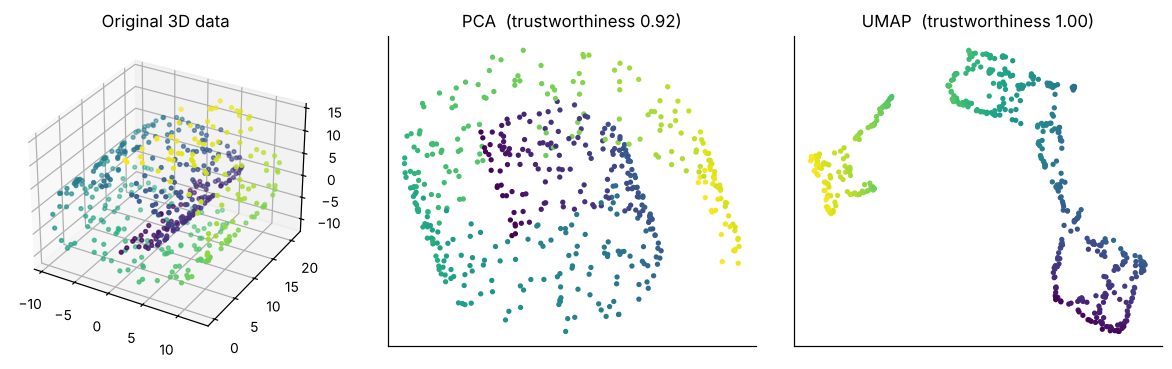

In [5]:
S, t = make_swiss_roll(n_samples=490, noise=0.05, random_state=0)
S_pca = PCA(n_components=2).fit_transform(S)
S_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(S)

fig = plt.figure(figsize=(11, 3.4))
ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.scatter(S[:, 0], S[:, 1], S[:, 2], c=t, cmap="viridis", s=6); ax.set_title("Original 3D data")
for i, (Z, name) in enumerate([(S_pca, "PCA"), (S_umap, "UMAP")], start=2):
    a = fig.add_subplot(1, 3, i)
    a.scatter(Z[:, 0], Z[:, 1], c=t, cmap="viridis", s=6)
    a.set_title(f"{name}  (trustworthiness {trustworthiness(S, Z, n_neighbors=10):.2f})")
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Reading the Swiss roll.** PCA squashes the roll flat, so layers that are far apart along the sheet land on top of each other (trustworthiness 0.92). UMAP follows the sheet and keeps neighbors together (trustworthiness 1.00), but it tears the sheet into pieces, so the global layout is not trustworthy. This matches the course slide: PCA preserves variance and global geometry, UMAP preserves local neighborhoods.

## 4. Data space vs. projection space

### 4a. The original high-dimensional space

We cannot plot 42 dimensions directly, so we use two standard views of the original space: a **correlation heatmap** of the numeric dimensions and **parallel coordinates** across the main dimensions, both colored by the same groups used in the projections later. To keep colors readable, scatter and line plots use three highlighted groups plus gray for everything else.

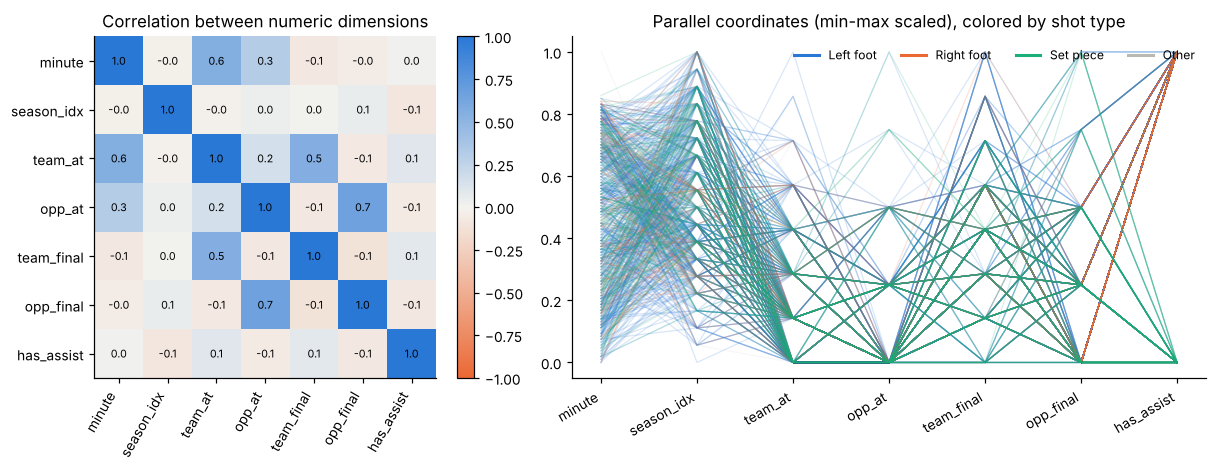

In [6]:
# Highlight groups (3 hues + gray "Other")
def shot_group(t):
    if t == "Left-footed shot": return "Left foot"
    if t == "Right-footed shot": return "Right foot"
    if t in ("Penalty", "Direct free kick", "Penalty rebound"): return "Set piece"
    return "Other"
df["Shot type"] = df["Type"].map(shot_group)
df["Competition focus"] = df["Competition"].where(df["Competition"].isin(
    ["LaLiga", "UEFA Champions League", "Copa del Rey"]), "Other")
df["Venue focus"] = df["Venue_Label"]
df["Club focus"] = df["Club"]

SHOT_COL = {"Left foot": BLUE, "Right foot": ORANGE, "Set piece": AQUA, "Other": GRAY}
COMP_COL = {"LaLiga": BLUE, "UEFA Champions League": ORANGE, "Copa del Rey": AQUA, "Other": GRAY}

div = LinearSegmentedColormap.from_list("div", [ORANGE, "#f4f3ef", BLUE])
dims = NUM + ["has_assist"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1, 1.5]})
corr = pd.concat([df[NUM], df[["has_assist"]]], axis=1).corr()
im = a1.imshow(corr, cmap=div, vmin=-1, vmax=1)
a1.set_xticks(range(len(dims))); a1.set_xticklabels(dims, rotation=60, ha="right")
a1.set_yticks(range(len(dims))); a1.set_yticklabels(dims)
for i in range(len(dims)):
    for j in range(len(dims)):
        a1.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
a1.set_title("Correlation between numeric dimensions"); plt.colorbar(im, ax=a1, fraction=0.046)

pcp = pd.concat([df[NUM], df[["has_assist"]]], axis=1)
pcp = (pcp - pcp.min()) / (pcp.max() - pcp.min())
order = ["Other", "Left foot", "Right foot", "Set piece"]
for g in order:
    for _, r in pcp[df["Shot type"] == g].iterrows():
        a2.plot(range(len(dims)), r.values, color=SHOT_COL[g], alpha=0.10 if g == "Other" else 0.18, lw=0.8)
a2.set_xticks(range(len(dims))); a2.set_xticklabels(dims, rotation=30, ha="right")
a2.set_title("Parallel coordinates (min-max scaled), colored by shot type")
handles = [plt.Line2D([0], [0], color=c, lw=2, label=k) for k, c in SHOT_COL.items()]
a2.legend(handles=handles, frameon=False, fontsize=8, loc="upper right", ncol=4)
plt.tight_layout(); plt.show()

**Reading the original space.** The strongest relationships among the numeric dimensions are score-related: `minute` correlates with `team_at` (0.6), `opp_at` with `opp_final` (0.7), and `team_at` with `team_final` (0.5), which is expected because goals later in a match come when more goals have already been scored. Season is nearly uncorrelated with everything else. The parallel-coordinates lines form a lattice at the score dimensions because scores are small integers, and `has_assist` has only two values. Shot types are mixed through all of this, with no obvious pattern in the original space.

### 4b. The two projections side by side

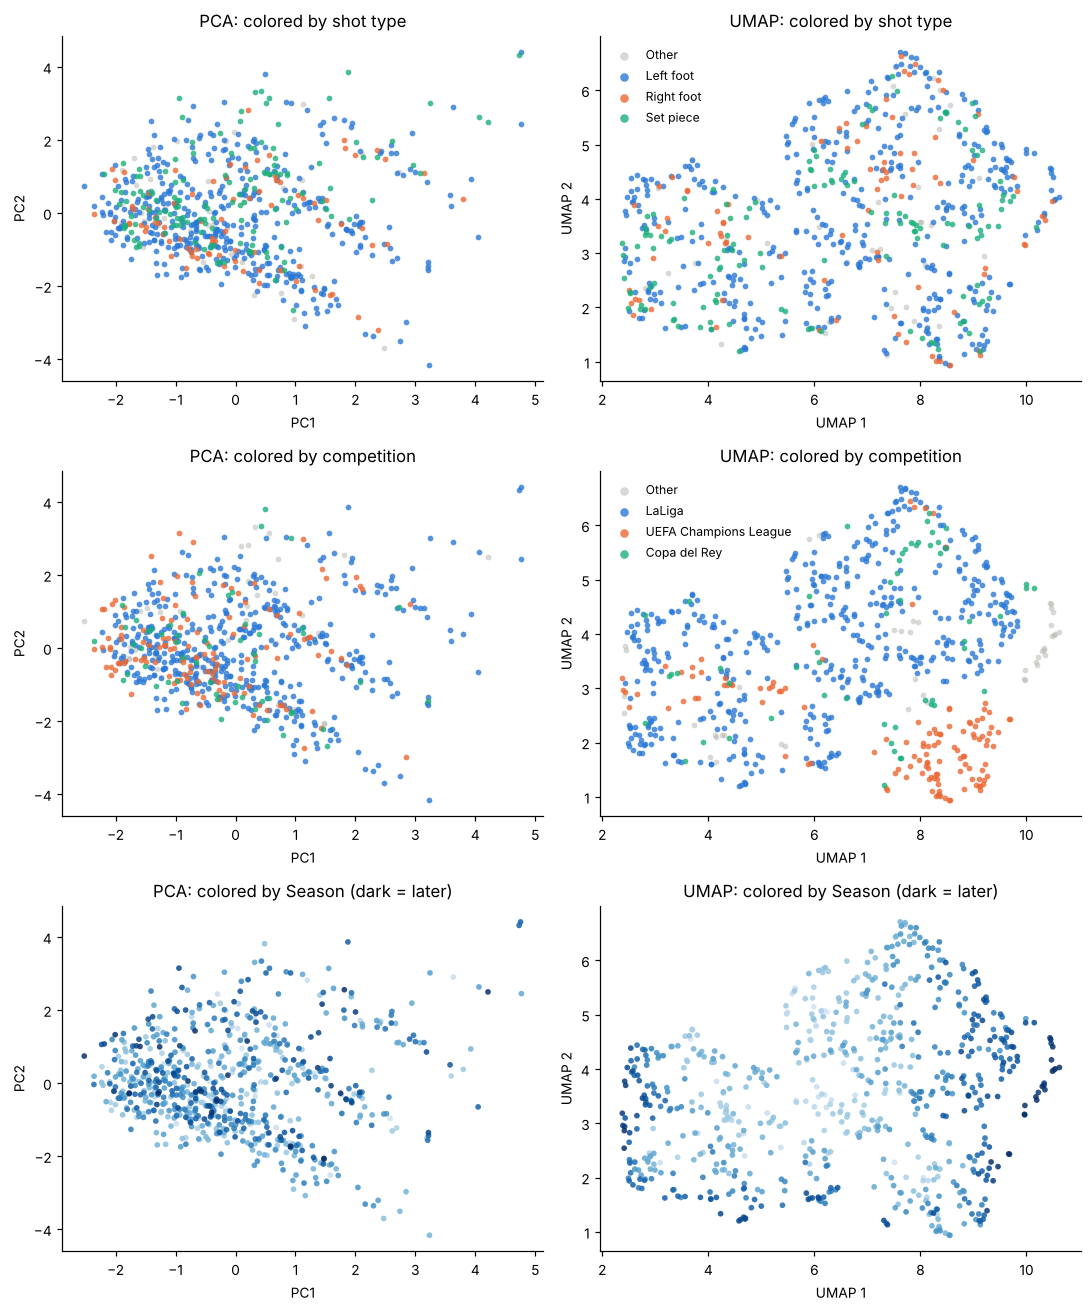

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(10, 12))
rows = [("Shot type", SHOT_COL, "Shot type"), ("Competition focus", COMP_COL, "Competition"), (None, None, "Season (dark = later)")]
for r, (col, pal, label) in enumerate(rows):
    for c, (Z, name, lab) in enumerate([(Z_pca, "PCA", ("PC1", "PC2")), (Z_umap, "UMAP", ("UMAP 1", "UMAP 2"))]):
        ax = axes[r, c]
        if col:
            for g in ["Other"] + [k for k in pal if k != "Other"]:
                m = (df[col] == g).values
                ax.scatter(Z[m, 0], Z[m, 1], s=14, color=pal[g], alpha=0.55 if g == "Other" else 0.8, label=g, linewidths=0)
        else:
            sc = ax.scatter(Z[:, 0], Z[:, 1], s=14, c=df["season_idx"], cmap="Blues", vmin=-3, alpha=0.85, linewidths=0)
        ax.set_title(f"{name}: colored by {label.lower() if col else label}")
        ax.set_xlabel(lab[0]); ax.set_ylabel(lab[1])
    if col: axes[r, 1].legend(frameon=False, fontsize=8, markerscale=1.5)
plt.tight_layout(); plt.show()

**Reading the maps.** The two methods organize the same 704 goals differently.

- **PCA** shows one elongated cloud with no separated groups. Colors for shot type and competition are heavily mixed, and season shows no gradient.
- **UMAP** shows three visible regions: a left lobe, a large middle/top region, and a compact group at lower right that is almost entirely Champions League goals (orange in the competition row). A thin group at the far right edge is mostly Paris Saint-Germain goals. The season row shows a gradient from earlier (light) to later (dark) seasons across the map.
- **Shot type separates in neither map.** Left foot, right foot, and set pieces are spread throughout both. That is a finding about our feature space: shot type is a few 0/1 columns among 42 dimensions, so it carries little weight compared with score and competition features.

### 4c. How faithful is each map? (quantitative check)

Two checks compare the original 42-dimensional space with each 2D map:

- **Trustworthiness** (0 to 1) asks whether points that are neighbors in the map were also neighbors in the original space. High values mean the local structure shown is real.
- **Shepard diagram:** original pairwise distance against map distance for every pair of goals. The Spearman correlation summarizes how well *global* distances are preserved.

,trustworthiness k=5,trustworthiness k=10,trustworthiness k=20,distance rank corr (Spearman),10-NN overlap
method,,,,,
PCA,0.828,0.827,0.826,0.714,0.159
UMAP,0.947,0.935,0.916,0.491,0.403


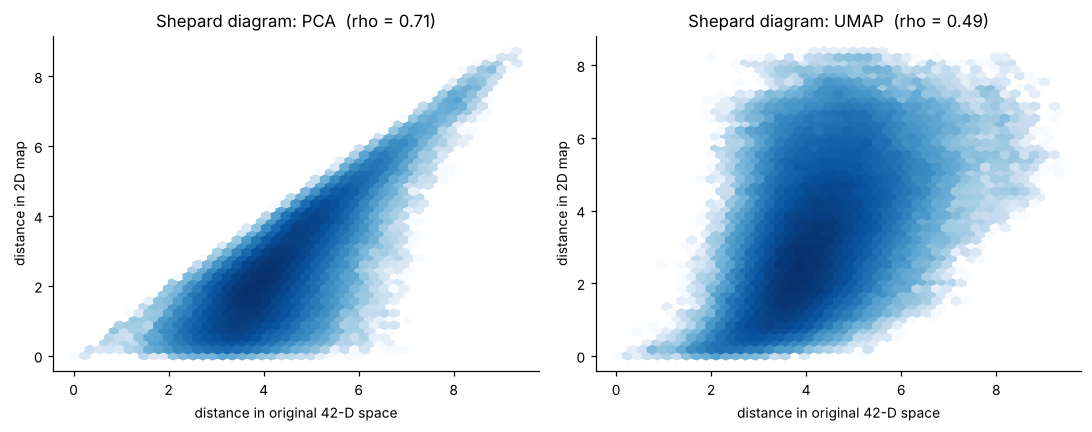

In [8]:
rows = []
for name, Z in [("PCA", Z_pca), ("UMAP", Z_umap)]:
    row = {"method": name}
    for k in (5, 10, 20):
        row[f"trustworthiness k={k}"] = trustworthiness(X, Z, n_neighbors=k)
    d_hi, d_lo = pdist(X), pdist(Z)
    row["distance rank corr (Spearman)"] = spearmanr(d_hi, d_lo).statistic
    nn_hi = NearestNeighbors(n_neighbors=11).fit(X).kneighbors(X, return_distance=False)[:, 1:]
    nn_lo = NearestNeighbors(n_neighbors=11).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
    row["10-NN overlap"] = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(nn_hi, nn_lo)])
    rows.append(row)
metrics = pd.DataFrame(rows).set_index("method").round(3)
display(metrics)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
d_hi = pdist(X)
for ax, (name, Z) in zip(axes, [("PCA", Z_pca), ("UMAP", Z_umap)]):
    ax.hexbin(d_hi, pdist(Z), gridsize=45, cmap="Blues", mincnt=1, bins="log")
    ax.set_xlabel("distance in original 42-D space"); ax.set_ylabel("distance in 2D map")
    ax.set_title(f"Shepard diagram: {name}  (rho = {metrics.loc[name, 'distance rank corr (Spearman)']:.2f})")
plt.tight_layout(); plt.show()

**Reading the metrics.** The two methods win on different criteria, as their objectives predict.

- **UMAP is much better locally.** Trustworthiness is 0.94 (k=10) against 0.83 for PCA, and 40% of a goal's 10 nearest neighbors in the original space are still its neighbors in the UMAP map, against 16% for PCA. UMAP optimizes neighborhood structure directly.
- **PCA is better globally.** Its distance rank correlation is 0.71 against 0.49 for UMAP, and the PCA Shepard diagram hugs a diagonal band. PCA can only shrink distances (a linear projection never stretches them), so map distance is a lower bound on original distance. UMAP's cloud shows that distances between groups in its picture are not reliable.
- **Neither is faithful in absolute terms.** Even PCA keeps only 16% of the 10-nearest-neighbor relationships, because 2 components capture 38% of the variance.

### 4d. What does each PCA axis mean?

PCA axes are linear combinations of the original features, so we can read them. UMAP axes have no such meaning. The bars show the features with the largest loadings.

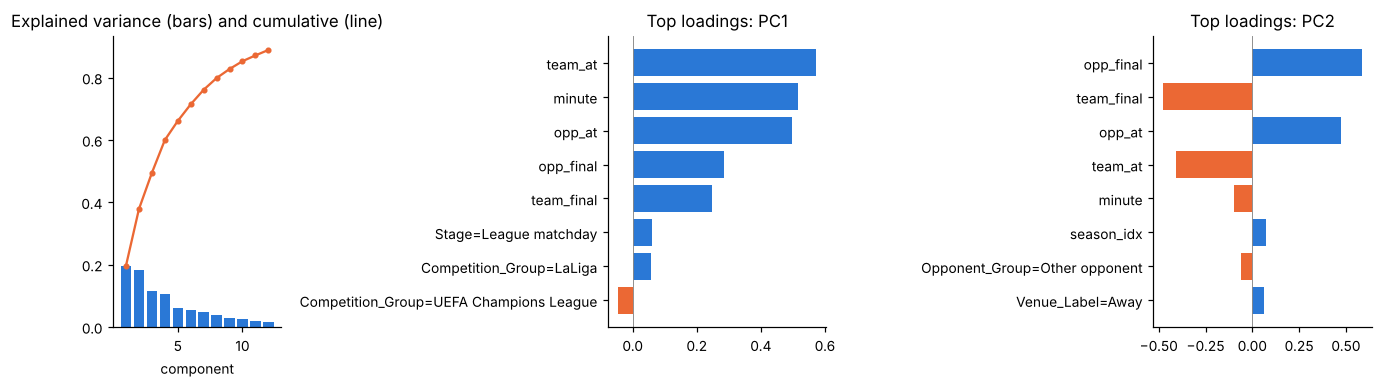

In [9]:
load = pd.DataFrame(pca.components_.T, index=X_df.columns, columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
cum = np.cumsum(pca_full.explained_variance_ratio_)
axes[0].bar(range(1, 13), pca_full.explained_variance_ratio_[:12], color=BLUE)
axes[0].plot(range(1, 13), cum[:12], color=ORANGE, marker="o", ms=3)
axes[0].set_title("Explained variance (bars) and cumulative (line)"); axes[0].set_xlabel("component")
for ax, pc in zip(axes[1:], ["PC1", "PC2"]):
    top = load[pc].reindex(load[pc].abs().sort_values(ascending=False).index[:8])[::-1]
    ax.barh(top.index, top.values, color=[BLUE if v > 0 else ORANGE for v in top.values])
    ax.set_title(f"Top loadings: {pc}"); ax.axvline(0, color="#888", lw=0.6)
plt.tight_layout(); plt.show()

**Reading the loadings.** Two components explain 38% of the variance, and 9 are needed to reach 80%, so no 2D map of this feature space can be complete. **PC1** (19.7%) is driven by `team_at`, `minute`, and `opp_at`: it orders goals by how late in the match they came and how many goals had already been scored. **PC2** (18.1%) contrasts `opp_final` and `opp_at` (positive) with `team_final` and `team_at` (negative): matches where the opponent scored versus one-sided wins.

Both axes are dominated by the z-scored numeric columns. This is a scaling effect: each z-scored column has variance 1, while a 0/1 column has variance at most 0.25, so PCA favors the numeric columns. This is why PCA does not show competition, club, or shot type structure. A different scaling would change the PCA result.

### 4e. Time as a third dimension: juxtaposing the UMAP map by era

The space-time cube survey (Bach et al.) describes **time juxtaposing**: cut the cube into time slices and lay them out side by side. Here each panel shows the same UMAP map with only one era highlighted, so we can see where in the map each period of his career lives. This is the static counterpart of the interactive season brush in Section 6.

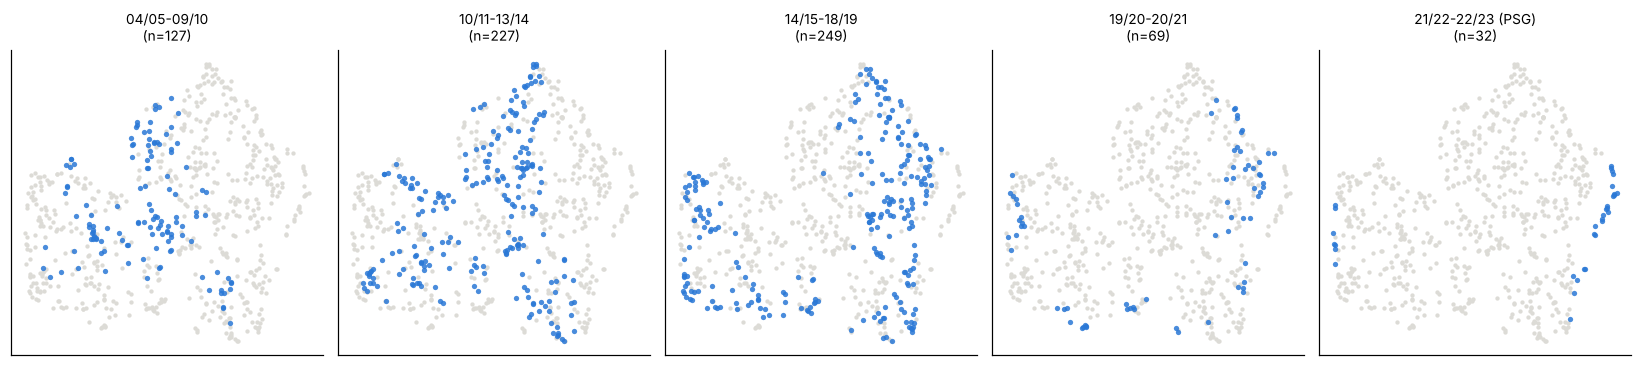

In [10]:
edges = [-1, 5, 9, 14, 16, 99]
era_names = ["04/05-09/10", "10/11-13/14", "14/15-18/19", "19/20-20/21", "21/22-22/23 (PSG)"]
df["era"] = pd.cut(df["season_idx"], bins=edges, labels=era_names)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4), sharex=True, sharey=True)
for ax, e in zip(axes, era_names):
    m = (df["era"] == e).values
    ax.scatter(Z_umap[~m, 0], Z_umap[~m, 1], s=8, color="#dcdbd6", linewidths=0)
    ax.scatter(Z_umap[m, 0], Z_umap[m, 1], s=12, color=BLUE, alpha=0.85, linewidths=0)
    ax.set_title(f"{e}\n(n={m.sum()})", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Reading the eras.** Each era occupies a different part of the UMAP map. The earliest seasons sit mostly in the left and middle regions, the later Barcelona seasons spread over the right side, and the two Paris seasons (21/22 and 22/23) concentrate along the right edge. Time is not a visible axis in PCA, so the era split shows structure that only the non-linear map exposes.

## 5. Does the UMAP picture depend on its settings?

A non-linear map can look very different with different settings, which is one of the "attractive embeddings can mislead" warnings from the course slides. We vary `n_neighbors` and check trustworthiness.

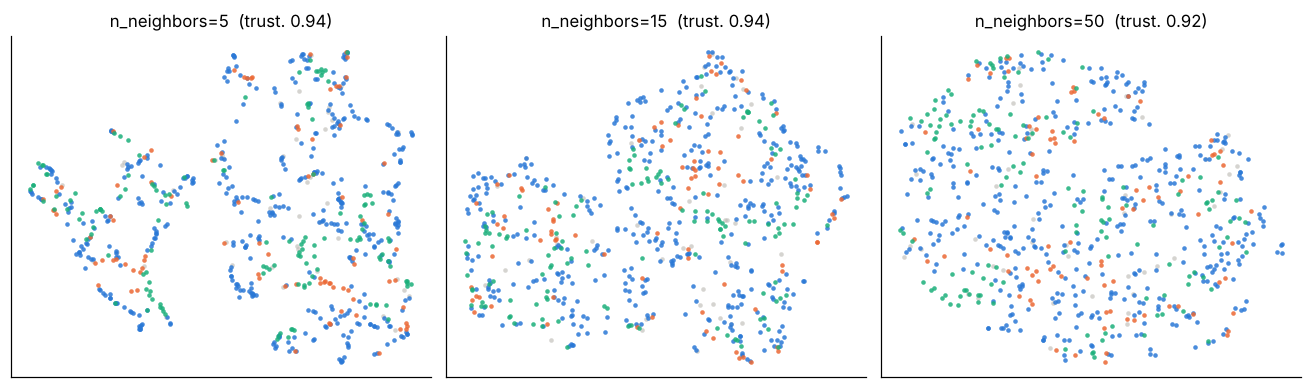

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, nn in zip(axes, [5, 15, 50]):
    Zt = umap.UMAP(n_neighbors=nn, min_dist=0.1, random_state=SEED).fit_transform(X)
    for g in ["Other", "Left foot", "Right foot", "Set piece"]:
        m = (df["Shot type"] == g).values
        ax.scatter(Zt[m, 0], Zt[m, 1], s=9, color=SHOT_COL[g], alpha=0.6 if g == "Other" else 0.85, linewidths=0)
    ax.set_title(f"n_neighbors={nn}  (trust. {trustworthiness(X, Zt, n_neighbors=10):.2f})")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Reading the sensitivity check.** With `n_neighbors=5` the map breaks into thin strands, with 15 it forms two large regions plus smaller groups, and with 50 it merges into a single cloud. Trustworthiness barely changes (0.94, 0.94, 0.92). So **the number of clusters in a UMAP picture is partly a setting, not a fact about the data**. We treat the groups we found as hypotheses and verify each against the original features (Section 8).

## 6. Interactive joint exploration

The dashboard below links **both projection spaces and the original feature space**. Everything is built with Altair (Vega-Lite), so the linking runs in the browser and works in the saved notebook as well as live.

**How to use it**

| Action | What happens in all other views |
|---|---|
| **Drag a box in the PCA map** or **in the UMAP map** | The goals inside the box stay colored everywhere, the rest turn gray. This shows where a PCA region lands in UMAP and the reverse. |
| **Drag across the season timeline** | Interactive time cutting: keep only goals from the chosen seasons (see Bach et al.). |
| **Click a bar** (shot type or competition) | Keep only that category. Shift-click to add more. |
| **Parallel coordinates** | Selected goals appear as colored lines across all original dimensions, so we see what the group looks like in the *original* space. |
| **Color by** dropdown | Recolors all views by shot type, competition, venue, or club. |
| **Hover a point** | Opponent, season, competition, minute, score, shot type, assist. |

Active selections combine with **AND**. To clear a box, click once on an empty part of that chart.

In [12]:
import json
from IPython.display import display

viz = df.reset_index(drop=True).copy()
viz["id"] = np.arange(len(viz))
viz["pc1"], viz["pc2"] = Z_pca[:, 0], Z_pca[:, 1]
viz["u1"], viz["u2"] = Z_umap[:, 0], Z_umap[:, 1]
viz["score"] = viz["team_final"].astype(str) + "-" + viz["opp_final"].astype(str)
viz["Assist"] = viz["Goal_assist"].fillna("none")
viz["Type"] = viz["Type"].fillna("Other")

# min-max scaled copies of the original dimensions for parallel coordinates
PC_DIMS = {"minute": "Minute", "season_idx": "Season (idx)", "team_at": "Team goals at goal", "opp_at": "Opp goals at goal",
           "team_final": "Team final", "opp_final": "Opp final", "has_assist": "Has assist"}
for k, v in PC_DIMS.items():
    viz[v] = (viz[k] - viz[k].min()) / (viz[k].max() - viz[k].min())
for c in ["Type_Clean", "Stage"]:
    pass
pc_cols = list(PC_DIMS.values())

domain = ["Left foot", "Right foot", "Set piece", "LaLiga", "UEFA Champions League", "Copa del Rey",
          "Home", "Away", "FC Barcelona", "Paris Saint-Germain", "Other"]
rng = [BLUE, ORANGE, AQUA, BLUE, ORANGE, AQUA, BLUE, ORANGE, BLUE, ORANGE, GRAY]
color_by = alt.param(name="ColorBy", value="Shot type",
                     bind=alt.binding_select(options=["Shot type", "Competition focus", "Venue focus", "Club focus"],
                                             name="Color by: "))

# --- selections (each is defined on exactly one view) ---
brush_pca  = alt.selection_interval(name="brush_pca",  encodings=["x", "y"])
brush_umap = alt.selection_interval(name="brush_umap", encodings=["x", "y"])
brush_time = alt.selection_interval(name="brush_time", encodings=["x"])
sel_type   = alt.selection_point(name="sel_type", fields=["Type_Clean"])
sel_comp   = alt.selection_point(name="sel_comp", fields=["Competition_Group"])
ALL = brush_pca & brush_umap & brush_time & sel_type & sel_comp

tips = [alt.Tooltip("Opponent:N"), alt.Tooltip("Season:N"), alt.Tooltip("Competition:N"), alt.Tooltip("Stage:N"),
        alt.Tooltip("minute:Q", title="Minute"), alt.Tooltip("score:N", title="Final score (Barca-Opp)"),
        alt.Tooltip("Type:N", title="Shot type"), alt.Tooltip("Assist:N", title="Assist")]

col_enc = alt.Color("grp:N", scale=alt.Scale(domain=domain, range=rng),
                    legend=alt.Legend(title="Color by (selected)", orient="right"))
GREY = "#d9d9d6"

def scatter(xf, yf, xt, yt, title, brush, legend=True):
    c = col_enc if legend else alt.Color("grp:N", scale=alt.Scale(domain=domain, range=rng), legend=None)
    return (alt.Chart(viz).transform_calculate(grp="datum[ColorBy]")
            .mark_circle(size=42)
            .encode(x=alt.X(f"{xf}:Q", title=xt, axis=alt.Axis(grid=False)),
                    y=alt.Y(f"{yf}:Q", title=yt, axis=alt.Axis(grid=False)),
                    color=alt.condition(ALL, c, alt.value(GREY)),
                    opacity=alt.condition(ALL, alt.value(0.9), alt.value(0.3)),
                    order=alt.condition(ALL, alt.value(1), alt.value(0)),
                    tooltip=tips)
            .add_params(brush).properties(width=330, height=330, title=title))

pca_chart  = scatter("pc1", "pc2", "PC1", "PC2", "PCA (linear): drag a box", brush_pca, legend=False)
umap_chart = scatter("u1", "u2", "UMAP 1", "UMAP 2", "UMAP (non-linear): drag a box", brush_umap)

# --- parallel coordinates in the ORIGINAL space ---
pcp_chart = (alt.Chart(viz).transform_calculate(grp="datum[ColorBy]")
             .transform_fold(pc_cols, as_=["dim", "val"])
             .mark_line(strokeWidth=1)
             .encode(x=alt.X("dim:N", sort=pc_cols, title=None, axis=alt.Axis(labelAngle=-25)),
                     y=alt.Y("val:Q", title="min-max scaled", axis=alt.Axis(grid=False)),
                     detail="id:N",
                     color=alt.condition(ALL, alt.Color("grp:N", scale=alt.Scale(domain=domain, range=rng), legend=None),
                                         alt.value(GREY)),
                     opacity=alt.condition(ALL, alt.value(0.35), alt.value(0.08)),
                     order=alt.condition(ALL, alt.value(1), alt.value(0)))
             .properties(width=700, height=220, title="Original feature space: parallel coordinates"))

# --- season timeline (time cutting) ---
season_labels = json.dumps(season_order)
tl_base = (alt.Chart(viz).mark_bar(color=GREY, size=16)
           .encode(x=alt.X("season_idx:Q", title="Season",
                           axis=alt.Axis(values=list(range(len(season_order))), labelAngle=-60,
                                         labelExpr=f"{season_labels}[datum.value]", grid=False)),
                   y=alt.Y("count():Q", title="goals")).add_params(brush_time))
tl_hi = (alt.Chart(viz).transform_filter(ALL).mark_bar(color=BLUE, size=16)
         .encode(x="season_idx:Q", y="count():Q"))
timeline = (tl_base + tl_hi).properties(width=330, height=170, title="Season timeline: drag to cut time")

def bars(field, sel, title, w):
    base = (alt.Chart(viz).mark_bar(color=GREY, cornerRadiusEnd=3)
            .encode(y=alt.Y(f"{field}:N", sort="-x", title=None), x=alt.X("count():Q", title="goals"))
            .add_params(sel))
    hi = (alt.Chart(viz).transform_filter(ALL).mark_bar(color=BLUE, cornerRadiusEnd=3)
          .encode(y=alt.Y(f"{field}:N", sort="-x"), x="count():Q"))
    return (base + hi).properties(width=w, height=170, title=title)

type_bars = bars("Type_Clean", sel_type, "Shot type: click", 190)
comp_bars = bars("Competition_Group", sel_comp, "Competition: click", 190)

# --- opponents among the selected goals (aggregate, so it updates cleanly) ---
opp_base = (alt.Chart(viz).mark_bar(color=GREY, cornerRadiusEnd=3)
            .encode(y=alt.Y("Opponent_Group:N", sort="-x", title=None), x=alt.X("count():Q", title="goals")))
opp_hi = (alt.Chart(viz).transform_filter(ALL).mark_bar(color=BLUE, cornerRadiusEnd=3)
          .encode(y=alt.Y("Opponent_Group:N", sort="-x"), x="count():Q"))
table = (opp_base + opp_hi).properties(width=330, height=200, title="Opponent of the selected goals (blue = selected)")
count_text = (alt.Chart(viz).transform_filter(ALL).transform_aggregate(n="count()")
              .mark_text(align="left", fontSize=16, fontWeight="bold", color="#333")
              .encode(text=alt.Text("n:Q", format="d")).properties(width=60, height=30, title="Selected"))

dashboard = (alt.vconcat(alt.hconcat(pca_chart, umap_chart),
                         pcp_chart,
                         alt.hconcat(timeline, type_bars, comp_bars, count_text),
                         table)
             .resolve_scale(color="shared").add_params(color_by)
             .configure_view(stroke=None).configure_title(fontSize=12, anchor="start"))
dashboard.save("messi_dr_dashboard.html")
dashboard

alt.VConcatChart(...)

A standalone copy of the dashboard is saved next to this notebook as `messi_dr_dashboard.html`. It opens in any browser without Python, which is useful if the notebook viewer does not render interactive charts.

## 7. Guided questions to try in the dashboard

Use these to check that the links work and to produce the findings in Section 8.

1. Drag a box around one dense UMAP group, then look at the PCA map. Do the same goals sit together in PCA, or are they spread out?
2. Select a region of the PCA map along PC1 and read the parallel coordinates and bar charts. Which original dimensions separate this region?
3. Brush the last two seasons on the timeline (21/22 and 22/23, his Paris seasons). Where do those goals fall in each map?
4. Click "Penalty" in the shot-type bars. Do penalties form one group in UMAP? In PCA?
5. Brush a box in PCA and a box in UMAP at once. The AND combination shows only goals that sit in both regions.

## 8. Analysis: what the two spaces show

We used the dashboard to name the UMAP regions and check them against the original features. The values below are computed from the data (group means in the original feature space).

| UMAP region (n) | What it contains in the original space | How it looks in PCA |
|---|---|---|
| **Left lobe** (214) | Goals scored after the opponent had already scored: mean opponent goals at the time is 1.30, against 0.04 to 0.07 in the other regions. Later in the match (mean minute 65, against 44 to 47). Mostly LaLiga (77%). | Mostly stays together (88% of a point's nearest PCA neighbors are in the same group), on the positive side of PC1 and PC2. |
| **Middle/top** (370) | Goals scored while the opponent still had no goal, mostly LaLiga (84%) with earlier minutes. | Stays fairly together (73%), overlapping heavily with the next group. |
| **Lower-right blob** (103) | 85% Champions League goals, 95% against opponents outside the top 8 by goal count. Earlier minutes (mean 44). | **Scattered**: only 28% of nearest PCA neighbors are in the same group. |
| **Far-right edge** (17) | 94% Paris Saint-Germain goals, later seasons (mean index 17.5 of 18). It holds 16 of Messi's 32 PSG goals. | **Not visible**: 2% of nearest PCA neighbors are in the same group. |

**What the linked views add.**
1. **PCA and UMAP agree on the score situation.** The left lobe (opponent already scored) is also recoverable in PCA, because that structure lives in the numeric columns that dominate PCA's variance.
2. **UMAP alone separates the Champions League and PSG groups.** These are driven by one-hot columns (competition, club, stage, opponent group), which PCA down-weights through its variance objective. Brushing the lower-right UMAP blob and checking PCA shows those goals scattered across it.
3. **The parallel-coordinates view confirms the groups are real in the original space**, not only artifacts of the map. For example, brushing the left lobe shows lines concentrated at opp_at >= 1.
4. **Shot type is not a major structure in this feature space.** Neither method separates left foot, right foot, and set pieces. A weighted feature set (or the shot x/y coordinates from the Hudl data) would be needed to study shot type with DR.

**Which method should the team use for which question?**
- To read axes and keep a global picture, use **PCA**: its axes are readable (Section 4d) and its distances are more trustworthy globally (rho 0.71).
- To look for groups of similar goals, use **UMAP**, then check the groups in the parallel-coordinates view. Do not trust group sizes or distances between groups.

## 9. Methodology, prompt strategy, and limitations

### Methodology summary
1. Cleaned `data.csv` (position, competition, season, minute, score columns) and engineered 42 features per goal.
2. Standardized numeric features, kept one-hot features as 0/1, applied **PCA** and **UMAP** to the same matrix.
3. Compared the maps to the original space with trustworthiness, 10-nearest-neighbor overlap, Shepard diagrams, parallel coordinates, and loadings.
4. Built a linked Altair dashboard with brushing, time cutting, categorical selection, and a color dropdown.

### Prompt strategy and AI use  *(team: edit this table to match what you actually did)*
| Step | Prompt (summary) | AI output | What we checked or changed |
|---|---|---|---|
| Data cleaning | *e.g. "Our `Result` column looks like times; how should we parse it?"* | *e.g. home:away score parsing* | *e.g. we verified against `Venue` and `At_score` (see assertions in Section 2)* |
| Method choice | *e.g. "Which linear and non-linear DR methods suit mixed categorical and numeric data?"* | | |
| Interaction design | *e.g. "How do we link brushing across two scatterplots in Altair?"* | | |

### Limitations
- Most features are binary one-hot columns, so many goals are identical or near-identical in feature space. That limits how finely any method can spread them.
- The feature set mixes numeric and categorical data with simple scaling. A dedicated mixed-data distance (such as Gower) could change the maps.
- Shot location is not in `data.csv`; adding the Hudl x/y data would add genuinely continuous dimensions.
- Clusters in a 2D map are hypotheses to check against the raw data, not proof.

## 10. Peer evaluation

Enter each member's contribution from 0% to 100%, including your own. *(Everyone submits their own evaluation; only one student submits the team notebook.)*

| Team member | Contribution (0-100%) | Main tasks |
|---|---|---|
| Essey Beraki | | |
| Sam Banstola | | |
| Luis Chavez | | |